# 1. Импорт библиотек

   student_id  age  gender   city_type  study_hours_per_day  \
0           0   21  Female  Semi-Urban                  3.2   
1           1   19  Female  Semi-Urban                  3.9   
2           2   16  Female       Urban                  4.3   
3           3   19    Male  Semi-Urban                  5.3   
4           4   17  Female       Urban                  4.1   

   deep_work_sessions  assignment_completion_rate  attendance_percentage  \
0                   7                         100                     70   
1                   2                          46                     70   
2                   7                          54                     57   
3                   1                          78                     90   
4                   3                         100                     81   

   social_media_hours  doomscrolling_before_sleep  ...  family_support  \
0                 3.8                           0  ...              10   
1               

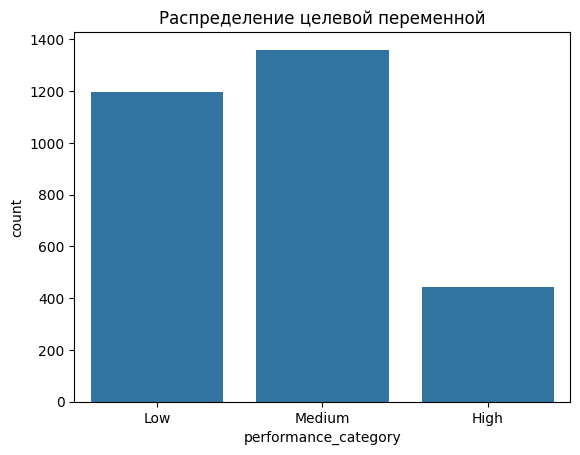

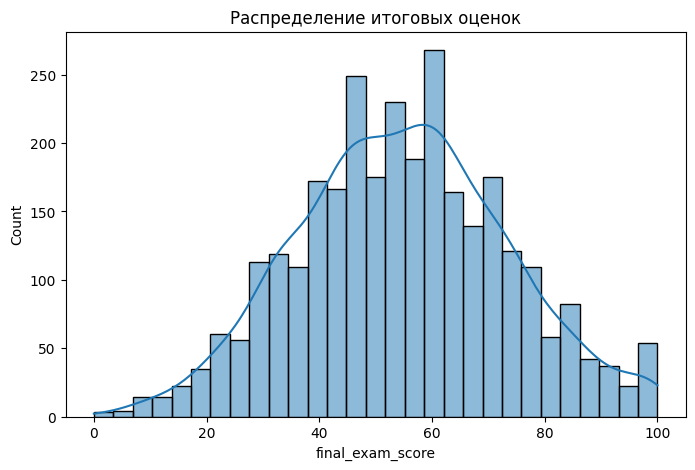

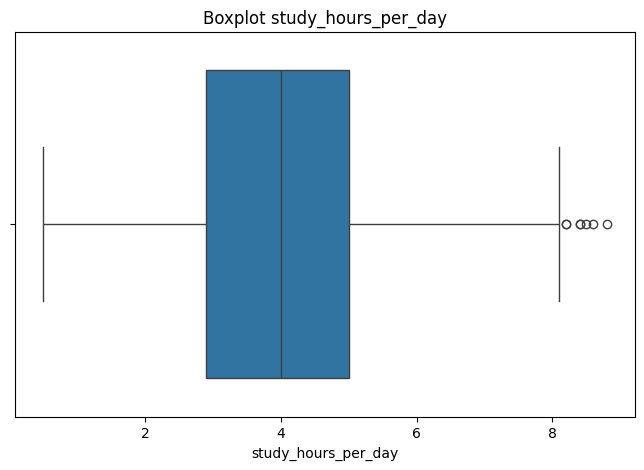

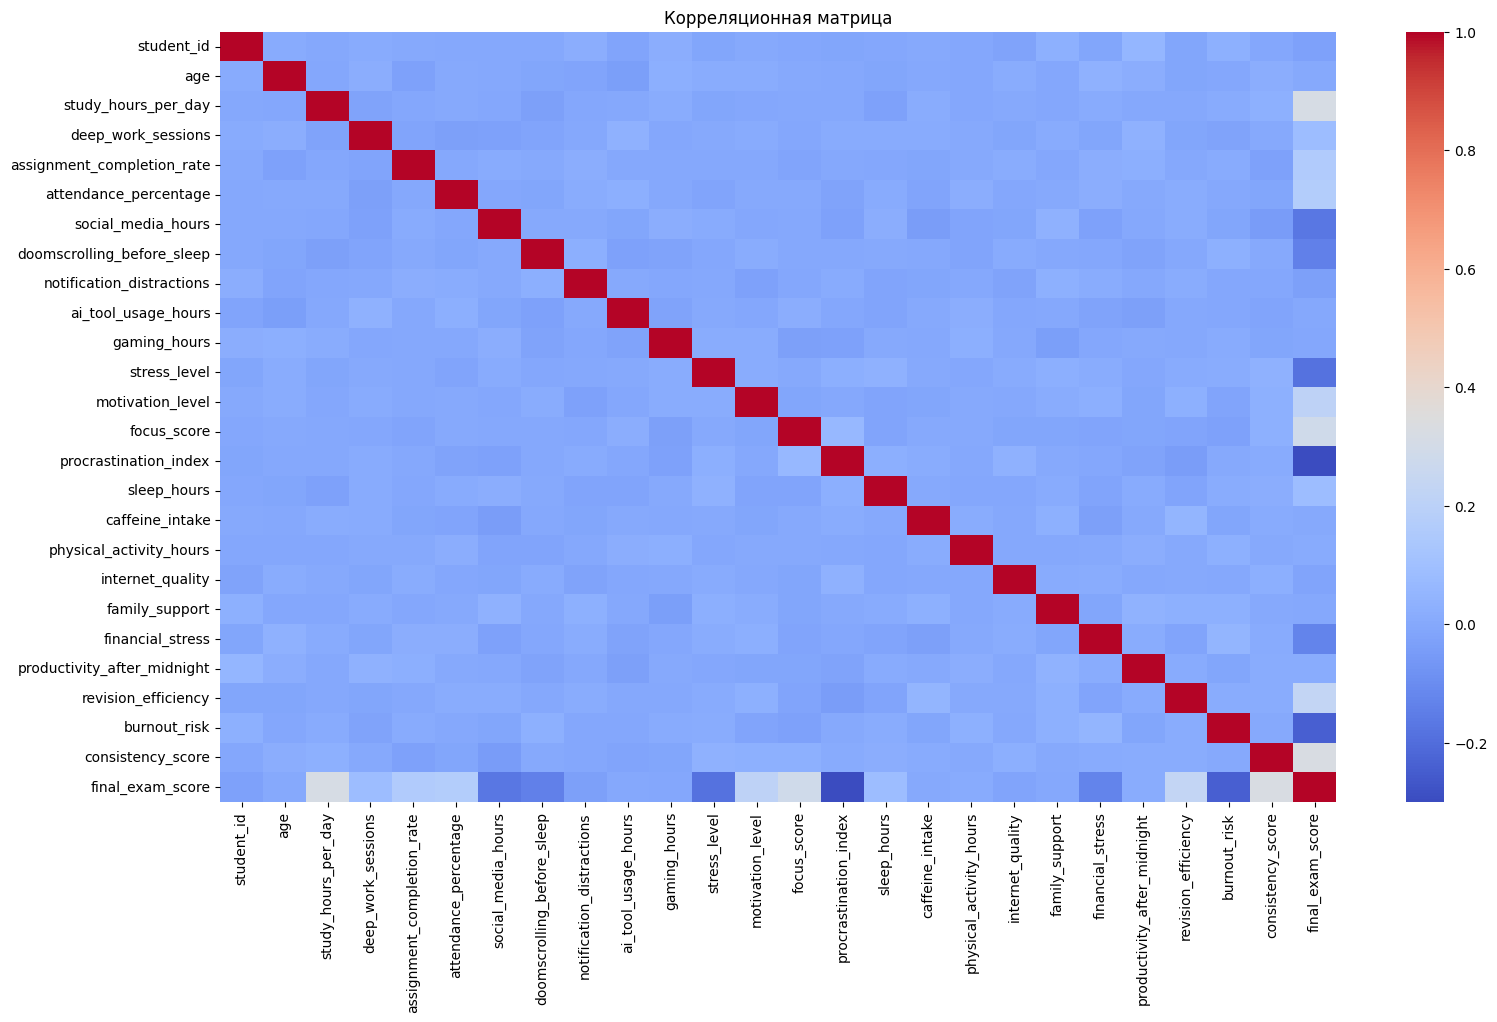

In [1298]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    LabelEncoder,
    OneHotEncoder,
    StandardScaler,
    MinMaxScaler,
    RobustScaler
)
from sklearn.metrics import RocCurveDisplay
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import label_binarize
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)



df = pd.read_csv('dataSet.csv')

# Первые 5 строк
print(df.head())
print(df.info())
print(df.describe())
print(df.shape)
print(df.isnull().sum())
print(df.duplicated().sum())
print(df['performance_category'].value_counts())
sns.countplot(x='performance_category', data=df)
plt.title('Распределение целевой переменной')
plt.show()
plt.figure(figsize=(8,5))

sns.histplot(df['final_exam_score'], kde=True)

plt.title('Распределение итоговых оценок')
plt.show()

plt.figure(figsize=(8,5))

sns.boxplot(x=df['study_hours_per_day'])

plt.title('Boxplot study_hours_per_day')
plt.show()
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

plt.figure(figsize=(18,10))

corr = df[numeric_cols].corr()

sns.heatmap(corr, cmap='coolwarm')

plt.title('Корреляционная матрица')
plt.show()

# 2. Генерация «грязных» данных

In [1299]:
df_dirty = df.copy()

np.random.seed(42)

missing_indices = np.random.choice(df_dirty.index, 100)

df_dirty.loc[missing_indices, 'sleep_hours'] = np.nan

duplicates = df_dirty.sample(20)

df_dirty = pd.concat([df_dirty, duplicates])

outlier_indices = np.random.choice(df_dirty.index, 20)

df_dirty.loc[outlier_indices, 'study_hours_per_day'] = 50

text_noise_indices = np.random.choice(df_dirty.index, 20)

for idx in text_noise_indices:
    df_dirty.loc[idx, 'gender'] = ' MAle '


plt.show()

# 3. Очистка данных

In [1300]:
def clean_data(df_clean):

    # Удаление дубликатов
    df_clean = df_clean.drop_duplicates()

    # Обработка пропусков
    numeric_cols = df_clean.select_dtypes(include=['int64', 'float64']).columns

    for col in numeric_cols:
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

    # Очистка текстовых данных
    cat_cols = df_clean.select_dtypes(include=['object']).columns

    for col in cat_cols:
        df_clean[col] = df_clean[col].str.lower().str.strip()

    # Исправление ошибок
    corrections = {
        'male ': 'male',
        ' male': 'male',
        ' maLe ': 'male'
    }

    for col in cat_cols:
        df_clean[col] = df_clean[col].replace(corrections)

    # Обработка выбросов
    Q1 = df_clean['study_hours_per_day'].quantile(0.25)
    Q3 = df_clean['study_hours_per_day'].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df_clean = df_clean[
        (df_clean['study_hours_per_day'] >= lower) &
        (df_clean['study_hours_per_day'] <= upper)
    ]

    return df_clean
df_clean = clean_data(df_dirty)
print(df_clean.isnull().sum())
print(df_clean.duplicated().sum())

student_id                     0
age                            0
gender                         0
city_type                      0
study_hours_per_day            0
deep_work_sessions             0
assignment_completion_rate     0
attendance_percentage          0
social_media_hours             0
doomscrolling_before_sleep     0
notification_distractions      0
ai_tool_usage_hours            0
gaming_hours                   0
stress_level                   0
motivation_level               0
focus_score                    0
procrastination_index          0
mental_state                   0
sleep_hours                    0
caffeine_intake                0
physical_activity_hours        0
internet_quality               0
family_support                 0
financial_stress               0
learning_style                 0
career_goal                    0
productivity_after_midnight    0
revision_efficiency            0
burnout_risk                   0
consistency_score              0
final_exam

# 4. Feature Engineering

In [1301]:
df_clean['study_focus_ratio'] = (
    df_clean['study_hours_per_day'] *
    df_clean['focus_score']
)

df_clean['stress_sleep_ratio'] = (
    df_clean['stress_level'] /
    (df_clean['sleep_hours'] + 1)
)
df_clean['is_high_attendance'] = (
    df_clean['attendance_percentage'] > 85
).astype(int)
df_clean['social_vs_study'] = (
    df_clean['social_media_hours'] /
    (df_clean['study_hours_per_day'] + 1)
)

# 5. Подготовка данных

In [1302]:
label_encoders = {}

cat_cols = df_clean.select_dtypes(include=['object']).columns

for col in cat_cols:

    encoder = LabelEncoder()

    df_clean[col] = encoder.fit_transform(df_clean[col])

    label_encoders[col] = encoder
X = df_clean.drop('performance_category', axis=1)
y = df_clean['performance_category']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
standard_scaler = StandardScaler()

X_train_standard = standard_scaler.fit_transform(X_train)
X_test_standard = standard_scaler.transform(X_test)
robust_scaler = RobustScaler()

X_train_robust = robust_scaler.fit_transform(X_train)
X_test_robust = robust_scaler.transform(X_test)
log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_standard, y_train)
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

# 7. Оценка качества моделей


In [1303]:
y_pred_log = log_model.predict(X_test_standard)
print(classification_report(y_test, y_pred_log))

print('Accuracy:', accuracy_score(y_test, y_pred_log))
print('Precision:', precision_score(y_test, y_pred_log, average='weighted'))
print('Recall:', recall_score(y_test, y_pred_log, average='weighted'))
print('F1-score:', f1_score(y_test, y_pred_log, average='weighted'))

y_pred_rf = rf_model.predict(X_test)
print(classification_report(y_test, y_pred_rf))
print('Accuracy:', accuracy_score(y_test, y_pred_rf))
print('Precision:', precision_score(y_test, y_pred_rf, average='weighted'))
print('Recall:', recall_score(y_test, y_pred_rf, average='weighted'))
print('F1-score:', f1_score(y_test, y_pred_rf, average='weighted'))


classes = np.unique(y_test)

y_test_bin = label_binarize(y_test, classes=classes)

              precision    recall  f1-score   support

           0       0.95      0.92      0.94        88
           1       0.99      0.99      0.99       238
           2       0.97      0.97      0.97       269

    accuracy                           0.97       595
   macro avg       0.97      0.96      0.97       595
weighted avg       0.97      0.97      0.97       595

Accuracy: 0.973109243697479
Precision: 0.9730046999913843
Recall: 0.973109243697479
F1-score: 0.9730075546171982
              precision    recall  f1-score   support

           0       1.00      0.95      0.98        88
           1       1.00      1.00      1.00       238
           2       0.99      1.00      0.99       269

    accuracy                           0.99       595
   macro avg       1.00      0.98      0.99       595
weighted avg       0.99      0.99      0.99       595

Accuracy: 0.9932773109243698
Precision: 0.9933758118632069
Recall: 0.9932773109243698
F1-score: 0.9932239470919235


# 8. Прогнозирование

In [1304]:
df_clean.describe()

,student_id,age,gender,city_type,study_hours_per_day,deep_work_sessions,assignment_completion_rate,attendance_percentage,social_media_hours,doomscrolling_before_sleep,...,productivity_after_midnight,revision_efficiency,burnout_risk,consistency_score,final_exam_score,performance_category,study_focus_ratio,stress_sleep_ratio,is_high_attendance,social_vs_study
count,2973.000000,2973.000000,2973.000000,2973.000000,2973.000000,2973.000000,2973.000000,2973.000000,2973.000000,2973.000000,...,2973.000000,2973.000000,2973.000000,2973.000000,2973.000000,2973.000000,2973.000000,2973.000000,2973.000000,2973.000000
mean,1499.846956,19.025900,0.494114,0.982509,3.980188,3.506223,69.936764,74.552304,2.950252,0.492768,...,5.550959,5.437605,5.532459,5.503532,54.745711,1.305079,21.923882,0.754854,0.281197,0.668703
std,867.096061,2.556429,0.500049,0.815209,1.488765,2.294526,17.571371,14.477870,1.494074,0.500032,...,2.863631,2.889024,2.841845,2.860202,18.690075,0.712391,14.637734,0.417319,0.449659,0.468731
min,0.000000,15.000000,0.000000,0.000000,0.500000,0.000000,40.000000,50.000000,0.000000,0.000000,...,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.500000,0.090909,0.000000,0.000000
25%,749.000000,17.000000,0.000000,0.000000,2.900000,1.000000,55.000000,62.000000,1.900000,0.000000,...,3.000000,3.000000,3.000000,3.000000,42.000000,1.000000,10.000000,0.400000,0.000000,0.370968
50%,1501.000000,19.000000,0.000000,1.000000,4.000000,4.000000,70.000000,74.000000,2.900000,0.000000,...,6.000000,5.000000,6.000000,6.000000,55.000000,1.000000,18.900000,0.746269,0.000000,0.592593
75%,2252.000000,21.000000,1.000000,2.000000,5.000000,5.000000,85.000000,87.000000,4.000000,1.000000,...,8.000000,8.000000,8.000000,8.000000,67.000000,2.000000,32.000000,1.066667,1.000000,0.853659
max,2999.000000,23.000000,1.000000,2.000000,8.100000,7.000000,100.000000,100.000000,8.900000,1.000000,...,10.000000,10.000000,10.000000,10.000000,100.000000,2.000000,78.000000,2.500000,1.000000,4.000000


In [1305]:
new_students = pd.DataFrame({
    'student_id': [5001, 5002],
    'age': [20, 18],
    'gender': ['male', 'female'],
    'city_type': ['urban', 'rural'],
    'study_hours_per_day': [7, 2],
    'deep_work_sessions': [5, 1],
    'assignment_completion_rate': [90, 40],
    'attendance_percentage': [95, 60],
    'social_media_hours': [1, 6],
    'doomscrolling_before_sleep': [0, 1],
    'notification_distractions': [2, 8],
    'ai_tool_usage_hours': [2, 0.5],
    'gaming_hours': [1, 5],
    'stress_level': [3, 9],
    'motivation_level': [9, 3],
    'focus_score': [8, 2],
    'procrastination_index': [2, 9],
    'mental_state': ['focused', 'distracted'],
    'sleep_hours': [8, 4],
    'caffeine_intake': [1, 5],
    'physical_activity_hours': [2, 0],
    'internet_quality': [9, 4],
    'family_support': [9, 3],
    'financial_stress': [2, 8],
    'learning_style': ['visual', 'reading'],
    'career_goal': ['engineering', 'arts'],
    'productivity_after_midnight': [5, 2],
    'revision_efficiency': [9, 3],
    'burnout_risk': [2, 8],
    'consistency_score': [9, 2],
    'final_exam_score': [85, 40],
    'performance_category': ['high', 'low'],
    'study_focus_ratio': [40, 13],
    'stress_sleep_ratio':[1.5, 0.7],
    'is_high_attendance':[1,0],
    'social_vs_study':[0.3, 1.05]
})
for col in cat_cols:
    new_students[col] = label_encoders[col].transform(new_students[col])
new_students = new_students.drop(columns=["performance_category"])
predictions = rf_model.predict(new_students)

print(predictions)

[0 1]
